In [1]:
import torch

print("="*50)

print("PyTorch :", torch.__version__)
print("CUDA :", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU :", torch.cuda.get_device_name(0))

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device :", device)

print("="*50)

PyTorch : 2.6.0+cu124
CUDA : True
GPU : NVIDIA GeForce GTX 1650
Device : cuda


In [2]:
!pip install timm tqdm seaborn scikit-learn

In [3]:
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import torch
import torch.nn as nn
import torch.optim as optim

from torchvision.datasets import ImageFolder
from torchvision import transforms
from torch.utils.data import DataLoader

import timm

from tqdm.auto import tqdm

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

In [4]:
dataset_path = "./datasets/imagenet-mini"

In [5]:
train_transform = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

test_transform = transforms.Compose([
    transforms.Resize((256,256)),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485,0.456,0.406],
        std=[0.229,0.224,0.225]
    )
])

In [6]:
train_dataset = ImageFolder(
    os.path.join(dataset_path,"train"),
    transform=train_transform
)

val_dataset = ImageFolder(
    os.path.join(dataset_path,"val"),
    transform=test_transform
)

In [7]:
train_loader = DataLoader(
    train_dataset,
    batch_size=32,
    shuffle=True,
    num_workers=0,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=0,
    pin_memory=True
)

In [8]:
classes = train_dataset.classes

print("Training Images :", len(train_dataset))
print("Validation Images :", len(val_dataset))

print("Classes :", len(classes))

Training Images : 34745
Validation Images : 3923
Classes : 1000


In [9]:
model = timm.create_model(
    "vit_base_patch16_224",
    pretrained=True
)

model = model.to(device)

print(model)

model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

c:\Users\ASUS\anaconda3\envs\dl\Lib\site-packages\huggingface_hub\file_download.py:139: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\ASUS\.cache\huggingface\hub\models--timm--vit_base_patch16_224.augreg2_in21k_ft_in1k. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


VisionTransformer(
  (patch_embed): PatchEmbed(
    (proj): Conv2d(3, 768, kernel_size=(16, 16), stride=(16, 16))
    (norm): Identity()
  )
  (pos_drop): Dropout(p=0.0, inplace=False)
  (patch_drop): Identity()
  (norm_pre): Identity()
  (blocks): Sequential(
    (0): Block(
      (norm1): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (attn): Attention(
        (qkv): Linear(in_features=768, out_features=2304, bias=True)
        (q_norm): Identity()
        (k_norm): Identity()
        (attn_drop): Dropout(p=0.0, inplace=False)
        (norm): Identity()
        (proj): Linear(in_features=768, out_features=768, bias=True)
        (proj_drop): Dropout(p=0.0, inplace=False)
      )
      (ls1): Identity()
      (drop_path1): Identity()
      (norm2): LayerNorm((768,), eps=1e-06, elementwise_affine=True)
      (mlp): Mlp(
        (fc1): Linear(in_features=768, out_features=3072, bias=True)
        (act): GELU(approximate='none')
        (drop1): Dropout(p=0.0, inplace=False

In [10]:
for param in model.parameters():
    param.requires_grad = False

In [11]:
for param in model.blocks[-1].parameters():
    param.requires_grad = True

In [12]:
model.head = nn.Linear(
    model.head.in_features,
    1000
)

model = model.to(device)

print(model.head)

Linear(in_features=768, out_features=1000, bias=True)


In [13]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=3e-5,
    weight_decay=1e-4
)

scheduler = optim.lr_scheduler.StepLR(
    optimizer,
    step_size=5,
    gamma=0.1
)

In [14]:
def train_one_epoch(model, loader, criterion, optimizer):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in tqdm(loader):

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(outputs, labels)

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        _, predicted = outputs.max(1)

        total += labels.size(0)

        correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [15]:
def evaluate(model, loader, criterion):

    model.eval()

    running_loss = 0

    correct = 0

    total = 0

    with torch.no_grad():

        for images, labels in tqdm(loader):

            images = images.to(device)

            labels = labels.to(device)

            outputs = model(images)

            loss = criterion(outputs, labels)

            running_loss += loss.item()

            _, predicted = outputs.max(1)

            total += labels.size(0)

            correct += predicted.eq(labels).sum().item()

    epoch_loss = running_loss / len(loader)

    epoch_acc = 100 * correct / total

    return epoch_loss, epoch_acc

In [16]:
num_epochs = 15

train_losses = []
val_losses = []

train_accs = []
val_accs = []

best_acc = 0

best_epoch = 0

best_train_loss = 0
best_val_loss = 0

best_train_acc = 0
best_val_acc = 0

for epoch in range(num_epochs):

    print(f"\nEpoch {epoch+1}/{num_epochs}")

    train_loss, train_acc = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer
    )

    val_loss, val_acc = evaluate(
        model,
        val_loader,
        criterion
    )

    scheduler.step()

    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Train Loss : {train_loss:.4f}")
    print(f"Train Accuracy : {train_acc:.2f}%")

    print(f"Validation Loss : {val_loss:.4f}")
    print(f"Validation Accuracy : {val_acc:.2f}%")

    if val_acc > best_acc:

        best_acc = val_acc

        best_epoch = epoch + 1

        best_train_loss = train_loss
        best_val_loss = val_loss

        best_train_acc = train_acc
        best_val_acc = val_acc

        torch.save(
            model.state_dict(),
            "./models/best_vit_imagenetmini.pth"
        )

        print("Best Model Saved")


Epoch 1/15


  0%|          | 0/1086 [00:00<?, ?it/s]

  0%|          | 0/123 [00:00<?, ?it/s]

Train Loss : 3.3069
Train Accuracy : 46.50%
Validation Loss : 1.1682
Validation Accuracy : 73.85%
Best Model Saved

Epoch 2/15


  0%|          | 0/1086 [00:00<?, ?it/s]

  0%|          | 0/123 [00:00<?, ?it/s]

... (36 outputs left out)

Train Loss : 0.5476
Train Accuracy : 87.24%
Validation Loss : 0.9907
Validation Accuracy : 77.26%

Epoch 15/15


  0%|          | 0/1086 [00:00<?, ?it/s]

  0%|          | 0/123 [00:00<?, ?it/s]

Train Loss : 0.5452
Train Accuracy : 87.31%
Validation Loss : 0.9908
Validation Accuracy : 77.26%


In [17]:
model.load_state_dict(
    torch.load(
        "./models/best_vit_imagenetmini.pth",
        map_location=device
    )
)

model.eval()

print("Best model loaded.")

Best model loaded.


In [18]:
all_labels = []

all_preds = []

with torch.no_grad():

    for images, labels in tqdm(val_loader):

        images = images.to(device)

        outputs = model(images)

        _, predicted = outputs.max(1)

        all_labels.extend(labels.numpy())

        all_preds.extend(predicted.cpu().numpy())

  0%|          | 0/123 [00:00<?, ?it/s]

In [19]:
accuracy = accuracy_score(all_labels, all_preds)

precision = precision_score(
    all_labels,
    all_preds,
    average="weighted"
)

recall = recall_score(
    all_labels,
    all_preds,
    average="weighted"
)

f1 = f1_score(
    all_labels,
    all_preds,
    average="weighted"
)

print("="*60)

print("Best Model Performance")

print("="*60)

print(f"Best Epoch : {best_epoch}")

print(f"Train Loss : {best_train_loss:.4f}")

print(f"Validation Loss : {best_val_loss:.4f}")

print(f"Train Accuracy : {best_train_acc:.2f}%")

print(f"Validation Accuracy : {best_val_acc:.2f}%")

print(f"Precision : {precision*100:.2f}%")

print(f"Recall : {recall*100:.2f}%")

print(f"F1 Score : {f1*100:.2f}%")

print("="*60)

Best Model Performance
Best Epoch : 12
Train Loss : 0.5498
Validation Loss : 0.9904
Train Accuracy : 87.30%
Validation Accuracy : 77.44%
Precision : 80.88%
Recall : 77.44%
F1 Score : 76.96%


c:\Users\ASUS\anaconda3\envs\dl\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


In [20]:
print(
    classification_report(
        all_labels,
        all_preds,
        target_names=classes
    )
)

              precision    recall  f1-score   support

   n01440764       1.00      1.00      1.00         3
   n01443537       1.00      0.67      0.80         3
   n01484850       1.00      1.00      1.00         5
   n01491361       1.00      0.67      0.80         3
   n01494475       0.67      0.80      0.73         5
   n01496331       1.00      0.67      0.80         3
   n01498041       0.75      1.00      0.86         3
   n01514668       1.00      0.67      0.80         3
   n01514859       0.75      1.00      0.86         3
   n01518878       1.00      1.00      1.00         3
   n01530575       1.00      1.00      1.00         4
   n01531178       1.00      1.00      1.00         4
   n01532829       1.00      1.00      1.00         3
   n01534433       1.00      1.00      1.00         4
   n01537544       1.00      1.00      1.00         4
   n01558993       1.00      1.00      1.00         3
   n01560419       1.00      1.00      1.00         3
   n01580077       1.00    

c:\Users\ASUS\anaconda3\envs\dl\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\anaconda3\envs\dl\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\ASUS\anaconda3\envs\dl\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])


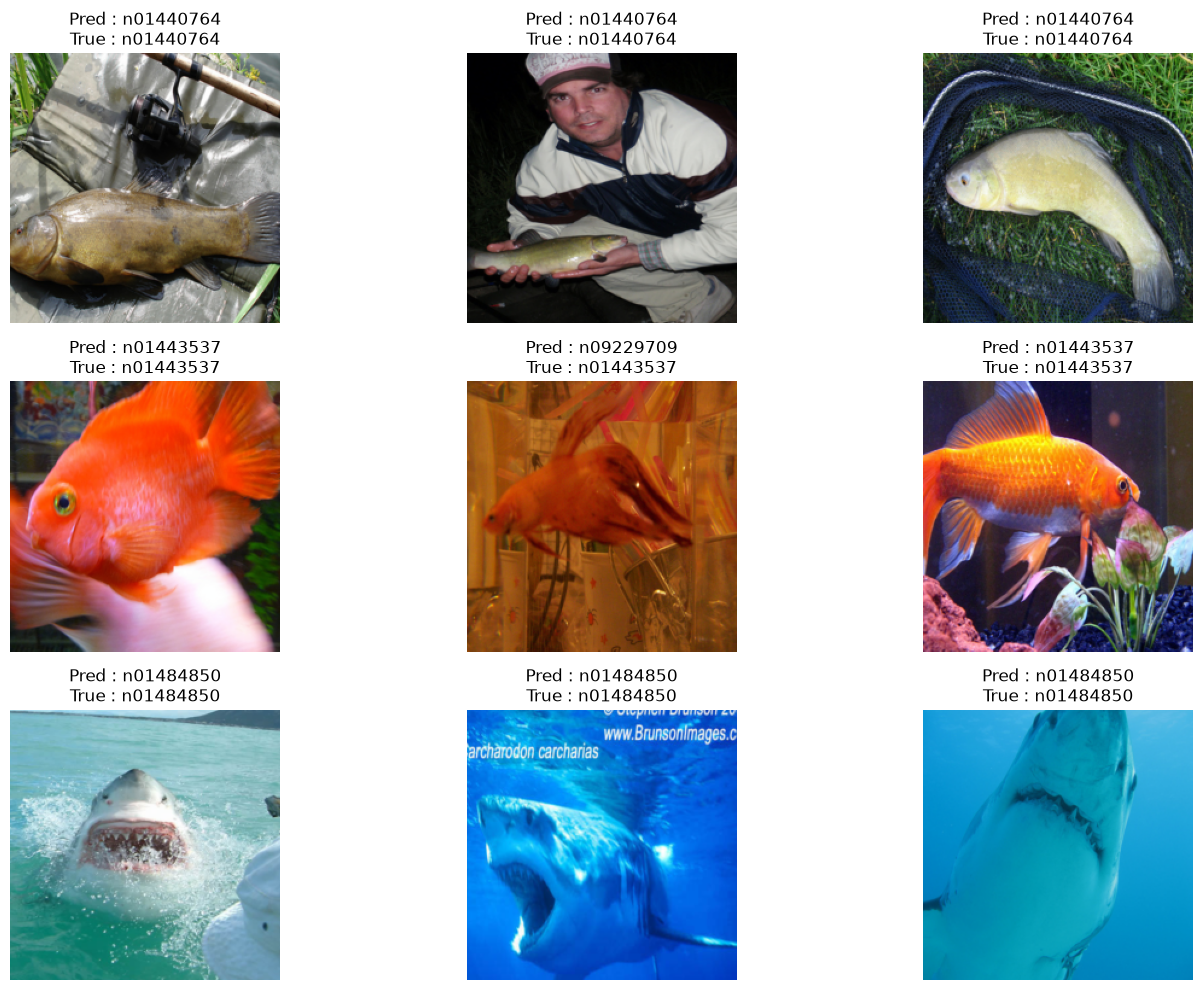

In [21]:
images, labels = next(iter(val_loader))

images = images.to(device)

outputs = model(images)

_, preds = outputs.max(1)

images = images.cpu()

plt.figure(figsize=(15,10))

for i in range(9):

    plt.subplot(3,3,i+1)

    img = images[i].permute(1,2,0).numpy()

    img = img * np.array([0.229,0.224,0.225]) + np.array([0.485,0.456,0.406])

    img = np.clip(img,0,1)

    plt.imshow(img)

    plt.title(
        f"Pred : {classes[preds[i]]}\nTrue : {classes[labels[i]]}"
    )

    plt.axis("off")

plt.tight_layout()

plt.show()

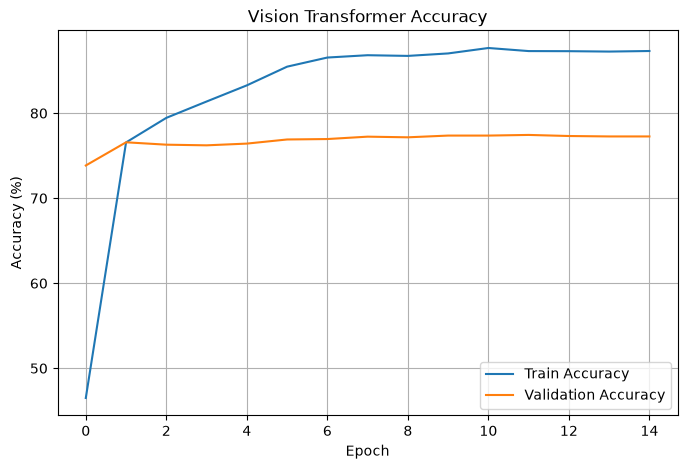

In [22]:
plt.figure(figsize=(8,5))

plt.plot(train_accs,label="Train Accuracy")

plt.plot(val_accs,label="Validation Accuracy")

plt.xlabel("Epoch")

plt.ylabel("Accuracy (%)")

plt.title("Vision Transformer Accuracy")

plt.legend()

plt.grid(True)

plt.show()

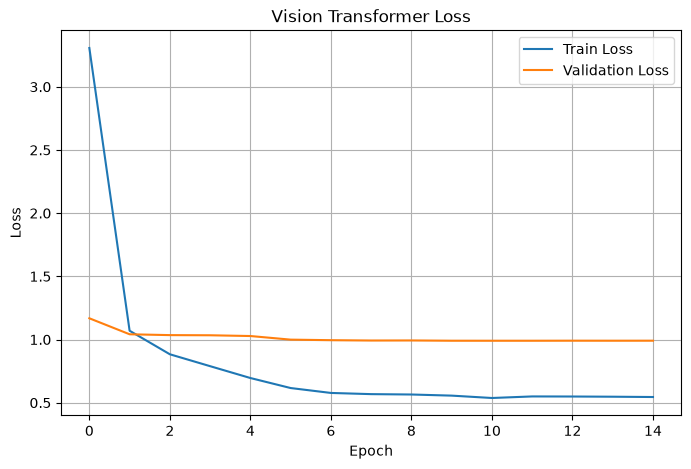

In [23]:
plt.figure(figsize=(8,5))

plt.plot(train_losses,label="Train Loss")

plt.plot(val_losses,label="Validation Loss")

plt.xlabel("Epoch")

plt.ylabel("Loss")

plt.title("Vision Transformer Loss")

plt.legend()

plt.grid(True)

plt.show()